# 01 Définition de la cible

On veut une colonne y pour chaque artiste. y vaut 1 s'il passe chez une major, 0 sinon. Ce notebook fabrique cette règle à partir des données.

Exemple. Un artiste sort un album chez un petit label en 2015, puis chez Columbia en 2019. Columbia appartient à Sony, donc il passe en major en 2019.

Pourquoi trois majors ? Depuis 2012 il n'en reste que trois, Universal, Sony et Warner. Les autres ont été absorbées. PolyGram a rejoint Universal en 1998, BMG a fusionné avec Sony en 2004, EMI a été partagée entre Universal et Warner en 2012 et 2013. Leurs labels sont donc déjà dans les trois groupes. Les autres gros labels sont indépendants.

Trois questions. Quels labels appartiennent aux majors (partie 1), quelles sorties comptent (partie 2), et quand observer (partie 3).

Données. Dump MusicBrainz `20261104-002222`, en parquet (`src/donnees.py`).

In [1]:
import sys

import pandas as pd

sys.path.append("..")
from src.transformation import (
    VARIANTES, artiste_principal, charger_sorties, cohorte, date_ajout, departs, garde,
    labels_majors_dates, labels_sous, liens_labels, lire, premiere_sortie_major, retenir,
    sans_distributeurs, sur_major,
)

## 1. Les labels des majors

Un disque porte le nom d'un label (Columbia), jamais celui de la major (Sony). Il faut donc savoir quels labels appartiennent à chaque major.

### Types de labels

In [2]:
label = lire("label", ["id", "gid", "name", "type"])
types = lire("label_type", ["id", "name"]).rename(columns={"id": "type", "name": "type_label"})
label = label.merge(types, on="type", how="left")
nom = label.set_index("id")["name"]

label["type_label"].value_counts(dropna=False, normalize=True).round(2)

type_label
NaN                    0.56
Original Production    0.15
Publisher              0.13
Production             0.06
Imprint                0.03
Distributor            0.03
Holding                0.02
Bootleg Production     0.01
Reissue Production     0.01
Manufacturer           0.00
Creative Agency        0.00
Rights Society         0.00
Broadcaster            0.00
Name: proportion, dtype: float64

56 % des labels n'ont pas de type. On ne peut pas filtrer par type, il faut suivre les liens entre labels.

### Liens entre labels

In [3]:
liens = liens_labels()

liens.groupby("type_lien").agg(
    nb=("link", "size"),
    avec_date=("begin_date_year", lambda s: s.notna().mean()),
).round(2)

,nb,avec_date
type_lien,,
imprint,5108,0.17
label distribution,4120,0.19
label ownership,22398,0.12
label reissue,368,0.33
label rename,2421,0.61


Les dates manquent presque toujours (12 % pour ownership). Quand elles existent, un label ne compte en major que pendant les dates de ses liens (notebook 02).

In [4]:
exemples = liens[liens["type_lien"] == "label ownership"].sample(5, random_state=0)
pd.DataFrame({
    "entity0": exemples["entity0"].map(nom),
    "phrase": exemples["long_link_phrase"],
    "entity1": exemples["entity1"].map(nom),
})

,entity0,phrase,entity1
33605,[PIAS] Entertainment Group,is/was the parent label of,Play It Again Sam
1202,Background,is/was the parent label of,Deep Night Essentials
16271,ズームリパブリック,is/was the parent label of,ズームリパブリック A事業部
20594,JMB DISTRUST GROUP,is/was the parent label of,Alex Froot Entertainment Records
18757,Real Music,is/was the parent label of,Real Mystic


entity0 possède entity1.

### On part des holdings

Une major est organisée en étages, comme des poupées russes. Exemple tiré de la base.

Universal Music Group > UNIVERSAL MUSIC LLC > UNIVERSAL SIGMA > Def Jam Recordings

Tout en haut, une holding. On part d'elle et on descend les liens jusqu'aux labels. Pour la trouver, on prend le label au nom de la major qui a le plus de liens.

In [5]:
liens_par_label = pd.concat([liens["entity0"], liens["entity1"]]).value_counts()
label["nb_liens"] = label["id"].map(liens_par_label).fillna(0).astype(int)

for major in ["Universal Music", "Sony Music", "Warner Music"]:
    candidats = label[label["name"].str.contains(major, regex=False)]
    display(candidats.nlargest(4, "nb_liens")[["id", "name", "type_label", "nb_liens"]])

,id,name,type_label,nb_liens
292910,151,Universal Music Group,Holding,207
310595,23463,Universal Music Publishing Group,Publisher,44
328146,53747,Universal Music GmbH,Holding,42
288008,62530,Universal Music Corp.,Publisher,33


,id,name,type_label,nb_liens
268072,87262,Sony Music Entertainment,Holding,100
310032,88432,Sony Music Entertainment Inc.,Holding,73
309455,366,Sony Music Entertainment (Japan) Inc.,Holding,62
261954,90223,Sony Music Labels Inc.,Holding,52


,id,name,type_label,nb_liens
123207,29,Warner Music Group Corp.,Holding,132
144690,124527,Warner Music Japan Inc.,Holding,53
266250,83917,Warner Music International Inc.,Holding,46
353191,1320,Warner Music UK Ltd.,Holding,29


Sony est un cas particulier.

In [6]:
sony = liens[liens["entity1"].isin([87262, 88432, 366]) & (liens["type_lien"] != "label distribution")]
pd.DataFrame({
    "entity0": sony["entity0"].map(nom),
    "lien": sony["type_lien"],
    "entity1": sony["entity1"].map(nom),
    "depuis": sony["begin_date_year"],
}).sort_values("depuis")

,entity0,lien,entity1,depuis
13450,Sony Corporation of America,label ownership,Sony Music Entertainment Inc.,1991
13554,CBS Records Inc.,label rename,Sony Music Entertainment Inc.,1991
16644,CBS/Sony Group Inc.,label rename,Sony Music Entertainment (Japan) Inc.,1991
26150,Sony Corporation,label ownership,Sony Music Entertainment (Japan) Inc.,1991
6094,Sony BMG Music Entertainment,label rename,Sony Music Entertainment,2009
33952,Sony Corporation of America,label ownership,Sony Music Entertainment,2009
28500,Sony Music Group,label ownership,Sony Music Entertainment,2019
27658,ソニーグループ株式会社,label ownership,Sony Music Entertainment (Japan) Inc.,2021


- Sony Japon n'est pas sous Sony Music, on l'ajoute à part.
- Sony Music a changé de nom (CBS Records, SME Inc., Sony BMG), on ajoute ses anciens noms.

In [7]:
MAJORS = departs(liens)
{m: list(nom[ids]) for m, ids in MAJORS.items()}

{'Universal': ['Universal Music Group', 'Universal Music'],
 'Sony': ['Sony Music Entertainment',
  'Sony Music Entertainment (Japan) Inc.',
  'Sony BMG Music Entertainment',
  'CBS/Sony Group Inc.',
  'Sony Music',
  'Sony Music Entertainment Inc.',
  'BMG',
  'CBS/Sony Inc.',
  'CBS Records Inc.',
  'RCA/Ariola International',
  'CBS/Sony Records Inc.'],
 'Warner': ['Warner Music Group Corp.', 'Warner Music Group']}

### Quels liens suivre ?

Plus on suit de types de liens, plus on rattache de labels aux majors, mais plus on se trompe. Le signe d'une erreur, c'est un label rattaché à deux majors à la fois (un doublon).

In [8]:
lignes = []
for types in VARIANTES.values():
    resultat = {m: labels_sous(liens, ids, types) for m, ids in MAJORS.items()}
    tous = []
    for labels in resultat.values():
        tous += list(labels)
    ligne = {m: len(labels) for m, labels in resultat.items()}
    ligne["profondeur max"] = max(max(labels.values()) for labels in resultat.values())
    ligne["doublons"] = (pd.Series(tous).value_counts() > 1).sum()
    lignes.append(ligne)

pd.DataFrame(lignes, index=list(VARIANTES))

,Universal,Sony,Warner,profondeur max,doublons
ownership,1548,849,897,9,42
+ imprint,1762,1112,1063,9,68
+ rename,2349,1896,1456,13,597
+ distribution,3742,4434,2255,19,2719
+ reissue,3828,4502,2284,19,2781


On garde ownership (possède) et imprint (une marque du label).

- Peu de doublons, et ils ne changent pas y. Universal ou Warner, c'est une major dans les deux cas.
- Suivre rename partout multiplie les doublons par 9 et rattache à Universal la branche américaine de Koch, qui en est indépendante (notebook 02).
- On ignore distribution. Un distributeur n'est pas propriétaire, le label reste indépendant. Pour la même raison, on retire les labels de type Distributor. Quelques filiales nationales typées ainsi partent avec, un compromis mesuré dans le notebook 02.
- On ignore reissue. Une réédition n'est pas une signature.

In [9]:
label_major = labels_majors_dates(liens, VARIANTES["+ imprint"])
distributeurs = label_major.loc[label_major["label"].map(label.set_index("id")["type_label"]) == "Distributor", "label"]
print(distributeurs.nunique(), "labels de type Distributor retirés")

label_major = sans_distributeurs(label_major)
print(label_major["label"].nunique(), "labels de majors")

182 labels de type Distributor retirés
3616 labels de majors


## 2. Les sorties qui comptent

Une sortie (release) est une édition d'un disque (release group). Un même disque peut avoir plusieurs éditions (pays, formats, rééditions).

### Dater une sortie

Les tables arrivent brutes. Dans `release_country`, tout est du texte, une sortie a une ligne par pays et sa date est parfois réduite à l'année. Exemple avec The Young and the Hopeless de Good Charlotte, sortie en France (73), en Suède (202) et en Europe (241).

In [10]:
brut = pd.read_parquet("../data/parquet/release_country.parquet", filters=[("release", "==", "400776")])
print(brut.dtypes)
brut

release       str
country       str
date_year     str
date_month    str
date_day      str
dtype: object


,release,country,date_year,date_month,date_day
0,400776,73,2002,10,1
1,400776,202,2003,2,17
2,400776,241,2002,NaN,NaN


In [11]:
release = charger_sorties()
print(f"Sorties avec une année : {release['annee'].notna().mean():.0%}")
release.loc[release["release"] == 400776, ["release", "annee", "statut", "type_principal", "label_connu", "reedition"]]

Sorties avec une année : 95%


,release,annee,statut,type_principal,label_connu,reedition
5290621,400776,2002,Official,Album,True,False


Après `charger_sorties`, il reste une ligne par sortie, typée et datée par l'année la plus ancienne de ses pays (2002 ici). On ne garde que l'année, le mois manque souvent.

### Sur une major ?

,avec un label connu,chez une major
annee,,
2000,0.83,0.15
2025,0.58,0.06


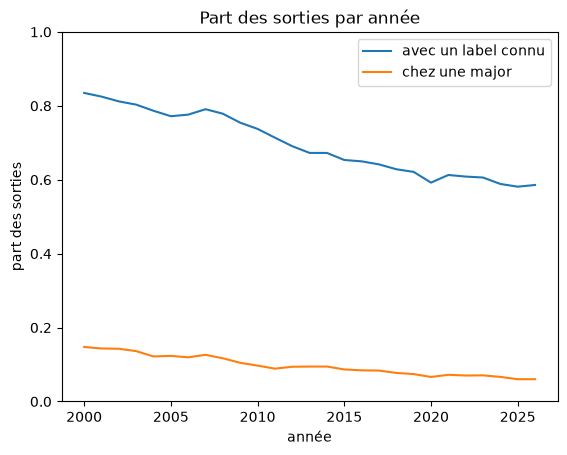

In [12]:
release["major"] = sur_major(release, label_major)

par_an = release[release["annee"].between(2000, 2026)].groupby("annee")[["label_connu", "major"]].mean()
par_an.columns = ["avec un label connu", "chez une major"]
par_an.plot(title="Part des sorties par année", ylim=(0, 1), xlabel="année", ylabel="part des sorties");
par_an.loc[[2000, 2025]].round(2)

`[no label]` veut dire autoédition. Un label vide veut dire inconnu.

Les labels sont de moins en moins renseignés (83 % des sorties en 2000, 58 % en 2025). Un artiste sans label connu n'est donc pas forcément indépendant.

### Filtrer les sorties

Certaines sorties feraient croire à tort qu'un artiste a signé. En moyenne 11 % des sorties officielles sont chez une major. Un type de sortie bien au-dessus, c'est en général du vieux catalogue remis en vente.

In [13]:
release.groupby("statut", dropna=False)["major"].agg(nb="size", part_major="mean").round(2)

,nb,part_major
statut,,
Bootleg,101095,0.01
Cancelled,645,0.1
Expunged,478,0.07
Official,5355234,0.11
Promotion,120889,0.19
Pseudo-Release,26919,0.03
Withdrawn,13363,0.14
NaN,285279,0.04


On garde Official. Les promos (19 % de majors) sont des copies d'autres sorties, et un bootleg n'est pas une sortie du label.

In [14]:
display(release.groupby("type_principal", dropna=False)["major"].agg(nb="size", part_major="mean").round(2))

secondaire = lire("release_group_secondary_type_join", ["release_group", "secondary_type"])
noms = lire("release_group_secondary_type", ["id", "name"]).set_index("id")["name"]
secondaire["type_secondaire"] = secondaire["secondary_type"].map(noms)
avec_secondaire = release.merge(secondaire[["release_group", "type_secondaire"]], on="release_group")
avec_secondaire.groupby("type_secondaire")["major"].agg(nb="size", part_major="mean").round(2).sort_values("part_major")

,nb,part_major
type_principal,,
Album,3282013,0.12
Broadcast,31654,0.0
EP,680981,0.03
Other,77872,0.08
Single,1723034,0.11
NaN,108348,0.02


,nb,part_major
type_secondaire,,
Field recording,1317,0.01
Demo,43449,0.01
Audiobook,23186,0.02
Interview,4365,0.03
Spokenword,21130,0.04
DJ-mix,41394,0.05
Mixtape/Street,22475,0.05
Live,216370,0.12
Soundtrack,146887,0.13


On garde Album, EP et Single, sans type secondaire. Les compilations (16 % de majors), live, remix et bandes originales sont des reprises de catalogue ou des disques collectifs.

In [15]:
release.groupby("major")["reedition"].mean().round(2)

major
False    0.06
True     0.16
Name: reedition, dtype: Float64

Une réédition sort après la première édition publiée du disque, sans compter les promos, bootlegs, pseudo-sorties et sorties annulées. 16 % des sorties de majors sont des rééditions, contre 6 % ailleurs. On les retire, car une major qui ressort un vieil album n'a pas signé l'artiste.

`release_group_meta` donne déjà la première date de chaque disque, mais n'écarte que les sorties annulées (statut 6, Cancelled, dans `get_release_first_release_date_rows` de `CreateFunctions.sql`). Une promo ou un bootleg sorti plus tôt y fait passer les éditions officielles pour des rééditions.

In [16]:
meta = lire("release_group_meta", ["id", "first_release_date_year"]).set_index("id")["first_release_date_year"]
avec_meta = (release["annee"] > release["release_group"].map(meta)).fillna(False)
a_tort = (release["statut"] == "Official") & avec_meta & ~release["reedition"]
print(f"{a_tort.sum()} sorties officielles passeraient pour des rééditions avec release_group_meta, {release.loc[a_tort, 'major'].mean():.0%} chez une major")

6276 sorties officielles passeraient pour des rééditions avec release_group_meta, 26% chez une major


Avec `release_group_meta`, 6 276 sorties officielles passeraient à tort pour des rééditions. 26 % d'entre elles sont chez une major, plus du double de la moyenne des sorties officielles.

In [17]:
print(f"{garde(release).sum()} sorties gardées sur {len(release)}")

3808518 sorties gardées sur 5903902

### Une édition isolée ne suffit pas

Un disque indépendant peut sortir chez une major dans un seul pays, par licence ou distribution. Arctic Monkeys (Domino) passerait ainsi en major avec l'édition mexicaine de AM (notebook 02). Une sortie ne compte donc en major que si la moitié au moins des éditions gardées de son disque y sont. Ce seuil est comparé à « toutes les éditions » dans le notebook 02.

In [18]:
gardees = retenir(release, label_major)
avant = (garde(release) & release["major"]).sum()
print(f"{gardees['major'].sum()} sorties en major sur {avant}, {1 - gardees['major'].sum() / avant:.0%} d'éditions isolées retirées")

337211 sorties en major sur 344959, 2% d'éditions isolées retirées


### Artiste principal

Sur « A feat. B », A est en position 0 et B est invité. On garde seulement l'artiste en position 0. On retire Various Artists et [unknown].

In [19]:
principal = artiste_principal()

### Combien de positifs ?

Un positif brut, c'est un artiste dont la première sortie en major arrive après au moins une sortie hors major.

les filtres retirent 11% à 39% des positifs bruts selon l'année


annee,2018,2019,2020,2021,2022,2023,2024,2025
toutes les sorties,819,870,814,932,856,821,894,737
sorties gardées,662,703,702,815,743,708,735,655


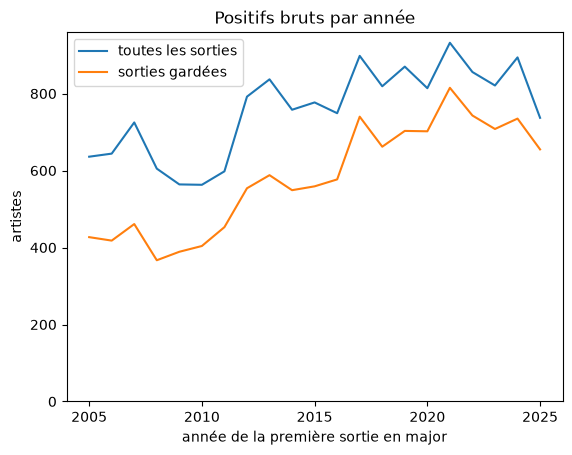

In [20]:
def passages_par_an(sorties):
    sorties = sorties.merge(principal, on="artist_credit")
    premiere = sorties.groupby("artist")["annee"].min()
    premiere_major = sorties[sorties["major"]].groupby("artist")["annee"].min()
    passage = premiere_major[premiere_major > premiere[premiere_major.index]]
    return passage.value_counts().sort_index()


comparaison = pd.DataFrame({
    "toutes les sorties": passages_par_an(release[release["annee"].notna()]),
    "sorties gardées": passages_par_an(gardees),
}).loc[2005:2025].astype(int)
comparaison.plot(title="Positifs bruts par année", xlabel="année de la première sortie en major", ylabel="artistes",
                 ylim=(0, None), xticks=range(2005, 2026, 5));
retires = 1 - comparaison["sorties gardées"] / comparaison["toutes les sorties"]
print(f"les filtres retirent {retires.min():.0%} à {retires.max():.0%} des positifs bruts selon l'année")
comparaison.loc[2018:].T

Les filtres retirent 11 à 39 % des positifs bruts selon l'année. Il en reste 655 à 815 par an de 2018 à 2025, ce qui suffit pour un modèle.

2026, pas finie, n'est pas tracée. Les années récentes sont peut-être sous-documentées, à vérifier avant de choisir T0.

## 3. Quand observer ?

On se place à une date T0. On regarde le passé de l'artiste pendant W ans avant T0, puis on regarde s'il sort chez une major pendant les H ans après T0.

```
[ T0-W ......... T0 [ T0 ......... T0+H [
   passé observé        fenêtre de cible
```

Une règle pour tout le projet. À T0, on n'utilise que ce que la base savait à T0. Sinon le modèle triche avec des informations du futur.

### La base se remplit en retard

La base ne garde pas la date d'ajout d'une sortie, on l'estime. Les identifiants sont croissants, donc une sortie a été ajoutée avant toutes celles qui ont un identifiant plus grand. Sa date d'ajout est au plus tard la plus petite date de mise à jour de ces sorties.

In [21]:
sorties = gardees.merge(date_ajout(), on="release")
sorties["delai"] = sorties["date_ajout"].dt.year - sorties["annee"]

recentes = sorties[sorties["annee"].between(2012, 2021)]
pd.DataFrame({
    k: recentes.groupby("annee")["delai"].apply(lambda d: (d <= k).fillna(False).mean())
    for k in [0, 1, 2, 3]
}).rename_axis(columns="part dans la base k ans après").round(2)

part dans la base k ans après,0,1,2,3
annee,,,,
2012,0.21,0.32,0.41,0.46
2013,0.21,0.34,0.41,0.48
2014,0.23,0.35,0.43,0.49
2015,0.25,0.37,0.44,0.50
2016,0.26,0.38,0.45,0.52
2017,0.26,0.39,0.47,0.55
2018,0.27,0.40,0.50,0.59
2019,0.28,0.43,0.54,0.63
2020,0.32,0.48,0.59,0.69


Une sortie de 2015 n'était dans la base qu'à 37 % un an après, et à 50 % trois ans après. La base se remplit des années après coup. Les années récentes paraissent mieux remplies (75 % pour 2021) seulement parce qu'elles n'ont pas encore reçu leurs ajouts tardifs.

### Le piège du passé ajouté après coup

Une cohorte, ce sont les artistes actifs dans les W ans avant T0. Ils ne sont jamais sortis avant T0 chez un label de major, même avant son rachat (notebook 02). Ses positifs sortent chez une major entre T0 et T0+H. On compare la cohorte vue avec la base actuelle et la cohorte vue avec la base telle qu'elle était à T0.

In [22]:
sorties = sorties.merge(principal, on="artist_credit")
premiere_major = premiere_sortie_major(sorties)

lignes = {}
for t0 in range(2014, 2024):
    actuelle = cohorte(sorties, t0, connu_a_t0=False)
    a_t0 = cohorte(sorties, t0)
    lignes[t0] = {
        "population actuelle": len(actuelle),
        "population à T0": len(a_t0),
        "positifs actuels": actuelle.sum(),
        "positifs à T0": a_t0.sum(),
        "part des positifs invisibles à T0": 1 - actuelle[actuelle].index.isin(a_t0.index).mean(),
    }
pd.DataFrame.from_dict(lignes, orient="index").round(2)

,population actuelle,population à T0,positifs actuels,positifs à T0,part des positifs invisibles à T0
2014,125928,41081,965,471,0.51
2015,133315,47075,996,520,0.48
2016,138655,51359,1124,530,0.53
2017,144668,56812,1273,587,0.54
2018,151491,61480,1318,620,0.53
2019,158235,66714,1453,691,0.52
2020,164780,71847,1484,701,0.53
2021,177364,82372,1553,719,0.54
2022,186011,92585,1509,736,0.51
2023,190588,102798,1434,770,0.46


Environ la moitié des positifs (46 à 54 %) n'avaient aucune sortie dans la base à T0. Leur passé a été ajouté après coup, sans doute une fois connus. Avec la base actuelle, le modèle apprendrait un raccourci (« bien documenté, donc va signer ») inutilisable en vrai. On ne garde donc que les sorties déjà dans la base à T0. Ce sera aussi la règle pour les variables.

Pour dire qu'un artiste n'est pas encore passé chez une major, on utilise quand même toute la base actuelle. On veut une cible propre.

### Combien d'années de passé (W) ?

In [23]:
avant = sorties[sorties["annee"] < sorties["artist"].map(premiere_major)]
ecart = premiere_major - avant.groupby("artist")["annee"].max()
ecart = ecart[premiere_major.between(2012, 2025)].dropna()

trois, cinq = cohorte(sorties, 2018), cohorte(sorties, 2018, w=5)
ajoutes = cinq.drop(trois.index)
print(f"W = 5 ajoute {len(ajoutes)} artistes à la cohorte 2018 ({len(trois)} avec W = 3), dont {ajoutes.sum()} positifs, "
      f"soit {ajoutes.mean():.2%} contre {trois.mean():.2%}")
pd.Series({k: (ecart <= k).mean() for k in [1, 2, 3, 5, 10]}).rename_axis("ans ou moins").round(2)

W = 5 ajoute 36260 artistes à la cohorte 2018 (61480 avec W = 3), dont 125 positifs, soit 0.34% contre 1.01%


ans ou moins
1     0.53
2     0.72
3     0.82
5     0.90
10    0.95
dtype: float64

82 % des positifs avaient sorti un disque dans les 3 ans avant leur première sortie en major, 90 % dans les 5 ans. On prend W = 3 ans. À 5 ans, la cohorte 2018 gagnerait 36 260 artistes sans sortie dans les 3 ans d'avant. Ils n'apportent que 125 positifs, 0,34 % contre 1,01 %.

### Quelle date T0 et quelle fenêtre de cible (H) ?

Nombre de positifs, puis taux de positifs en %, selon T0 (lignes) et H (colonnes).

In [24]:
positifs, taux = {}, {}
for t0 in range(2014, 2024):
    positifs[t0], taux[t0] = {}, {}
    for h in range(1, 6):
        if t0 + h - 1 <= 2025:
            c = cohorte(sorties, t0, h=h)
            positifs[t0][h], taux[t0][h] = c.sum(), 100 * c.mean()

display(pd.DataFrame(positifs).T.astype("Int64"))
pd.DataFrame(taux).T.round(2)

,1,2,3,4,5
2014,186,344,471,607,695
2015,205,366,520,634,735
2016,202,393,530,667,770
2017,236,425,587,717,844
2018,243,462,620,781,892
2019,275,482,691,821,930
2020,285,543,701,833,965
2021,322,546,719,896,1029
2022,286,512,736,899,<NA>
2023,300,575,770,<NA>,<NA>


,1,2,3,4,5
2014,0.45,0.84,1.15,1.48,1.69
2015,0.44,0.78,1.10,1.35,1.56
2016,0.39,0.77,1.03,1.30,1.50
2017,0.42,0.75,1.03,1.26,1.49
2018,0.40,0.75,1.01,1.27,1.45
2019,0.41,0.72,1.04,1.23,1.39
2020,0.40,0.76,0.98,1.16,1.34
2021,0.39,0.66,0.87,1.09,1.25
2022,0.31,0.55,0.79,0.97,NaN
2023,0.29,0.56,0.75,NaN,NaN


- H = 3 ans. Avec 1 an, trop peu de positifs (186 à 322, moins de 0,5 %). Avec 3 ans, 471 à 770 par cohorte, environ 0,75 à 1,15 %.
- Test sur la cohorte T0 = 2021 (cible 2021 à 2023). On garde 2024 comme marge, car les positifs de 2025 baissent déjà (partie 2), signe d'une base pas encore remplie.
- Entraînement sur les cohortes T0 = 2014 à 2018. Leurs cibles finissent avant 2021, donc le test porte vraiment sur le futur.
- Le taux baisse avec le temps (1,15 % en 2014, 0,87 % en 2021) car la base couvre de plus en plus de petits artistes. Tester sur une cohorte récente mesure ce décalage.
- Pas de creux pour les cohortes 2019 et 2020, donc pas d'effet Covid visible.
- Environ 1 % de positifs, les classes sont très déséquilibrées. On jugera les modèles avec la précision et le rappel, pas avec l'exactitude.

## Suite

1. Vérifier la règle sur des artistes connus, avec les dates des liens et les contrats « recording contract » (notebook 02).
2. Construire les variables, seulement avec ce que la base savait à T0.

## Sources

- Le calcul de la première date d'un disque, https://github.com/metabrainz/musicbrainz-server/blob/master/admin/sql/CreateFunctions.sql